In [1]:
from google.colab import files

uploaded = files.upload()

Saving HomeCredit_columns_description.csv to HomeCredit_columns_description.csv


In [3]:
import pandas as pd

columns_desc = pd.read_csv(
    "HomeCredit_columns_description.csv",
    encoding="latin-1"
)

display(columns_desc.head(10))
print("Ukuran:", columns_desc.shape)
print("Nama kolom:", columns_desc.columns.tolist())

,Unnamed: 0,Table,Row,Description,Special
0,1,application_{train|test}.csv,SK_ID_CURR,ID of loan in our sample,NaN
1,2,application_{train|test}.csv,TARGET,Target variable (1 - client with payment diffi...,NaN
2,5,application_{train|test}.csv,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
3,6,application_{train|test}.csv,CODE_GENDER,Gender of the client,NaN
4,7,application_{train|test}.csv,FLAG_OWN_CAR,Flag if the client owns a car,NaN
5,8,application_{train|test}.csv,FLAG_OWN_REALTY,Flag if client owns a house or flat,NaN
6,9,application_{train|test}.csv,CNT_CHILDREN,Number of children the client has,NaN
7,10,application_{train|test}.csv,AMT_INCOME_TOTAL,Income of the client,NaN
8,11,application_{train|test}.csv,AMT_CREDIT,Credit amount of the loan,NaN
9,12,application_{train|test}.csv,AMT_ANNUITY,Loan annuity,NaN


Ukuran: (219, 5)
Nama kolom: ['Unnamed: 0', 'Table', 'Row', 'Description', 'Special']


In [4]:
import os

print("File yang tersedia:")
print(os.listdir())

File yang tersedia:
['.config', 'HomeCredit_columns_description.csv', 'sample_data']


In [6]:
from google.colab import files

uploaded = files.upload()

Saving application_train.csv to application_train.csv


Baca dataset utama

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("application_train.csv")

print("Jumlah baris dan kolom:", df.shape)
display(df.head())

Jumlah baris dan kolom: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


periksa kualitas data

In [8]:
print("Jumlah data duplikat:", df.duplicated().sum())
print("Jumlah ID unik:", df["SK_ID_CURR"].nunique())
print("Jumlah missing value:", df.isna().sum().sum())

missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2)
}).sort_values("Missing (%)", ascending=False)

display(missing.head(15))

Jumlah data duplikat: 0
Jumlah ID unik: 307511
Jumlah missing value: 9152465


,Missing Count,Missing (%)
COMMONAREA_AVG,214865,69.87
COMMONAREA_MODE,214865,69.87
COMMONAREA_MEDI,214865,69.87
NONLIVINGAPARTMENTS_MEDI,213514,69.43
NONLIVINGAPARTMENTS_MODE,213514,69.43
NONLIVINGAPARTMENTS_AVG,213514,69.43
FONDKAPREMONT_MODE,210295,68.39
LIVINGAPARTMENTS_AVG,210199,68.35
LIVINGAPARTMENTS_MEDI,210199,68.35
LIVINGAPARTMENTS_MODE,210199,68.35


Analisis target gagal bayar

In [9]:
target_summary = pd.DataFrame({
    "Jumlah": df["TARGET"].value_counts().sort_index(),
    "Persentase (%)": (
        df["TARGET"].value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
})

display(target_summary)

,Jumlah,Persentase (%)
TARGET,,
0,282686,91.93
1,24825,8.07


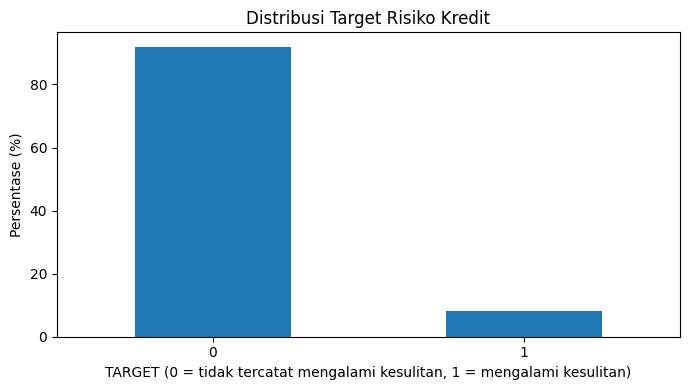

In [10]:
target_summary["Persentase (%)"].plot(
    kind="bar",
    figsize=(7, 4),
    rot=0
)

plt.title("Distribusi Target Risiko Kredit")
plt.xlabel("TARGET (0 = tidak tercatat mengalami kesulitan, 1 = mengalami kesulitan)")
plt.ylabel("Persentase (%)")
plt.tight_layout()
plt.show()

Apa artinya bagi bisnis?
- Sekitar 8 dari setiap 100 pengajuan dalam dataset termasuk kategori TARGET 1.
- Data tidak seimbang: jumlah TARGET 0 sekitar 11,39 kali jumlah TARGET 1.
- Model yang selalu memprediksi TARGET 0 bisa memperoleh akurasi sekitar 91,93%, tetapi gagal mendeteksi seluruh kategori TARGET 1.
Karena itu, kita tidak boleh hanya mengandalkan akurasi. Nanti kita akan mengevaluasi recall, precision, ROC-AUC, PR-AUC, dan kalibrasi probabilitas.
Perlu diingat, TARGET 1 merupakan indikator kesulitan pembayaran sesuai definisi dataset Home Credit, bukan bukti bahwa nasabah pasti gagal membayar pinjaman Pindar di Indonesia.

Analisis kualitas data

In [11]:
# 1. Ukuran dataset
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

# 2. Pemeriksaan duplikasi
print("Baris duplikat:", df.duplicated().sum())
print("ID unik:", df["SK_ID_CURR"].nunique())

# 3. Ringkasan missing values
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2)
})

missing = missing.sort_values(
    "Missing (%)", ascending=False
)

display(missing.head(15))

# 4. Tipe data
display(
    df.dtypes.value_counts().rename_axis("Tipe Data")
    .reset_index(name="Jumlah Kolom")
)

Jumlah baris: 307511
Jumlah kolom: 122
Baris duplikat: 0
ID unik: 307511


,Missing Count,Missing (%)
COMMONAREA_AVG,214865,69.87
COMMONAREA_MODE,214865,69.87
COMMONAREA_MEDI,214865,69.87
NONLIVINGAPARTMENTS_MEDI,213514,69.43
NONLIVINGAPARTMENTS_MODE,213514,69.43
NONLIVINGAPARTMENTS_AVG,213514,69.43
FONDKAPREMONT_MODE,210295,68.39
LIVINGAPARTMENTS_AVG,210199,68.35
LIVINGAPARTMENTS_MEDI,210199,68.35
LIVINGAPARTMENTS_MODE,210199,68.35


,Tipe Data,Jumlah Kolom
0,float64,65
1,int64,41
2,object,16


Insight penting
Variabel dengan missing value tertinggi, seperti COMMONAREA_AVG, NONLIVINGAPARTMENTS_AVG, dan YEARS_BUILD_AVG, berkaitan dengan karakteristik properti atau tempat tinggal.

Analisis missing value

In [12]:
# Kelompokkan kolom berdasarkan tingkat missing value
missing["Kategori"] = pd.cut(
    missing["Missing (%)"],
    bins=[-0.01, 5, 30, 60, 100],
    labels=[
        "Rendah (<=5%)",
        "Sedang (>5-30%)",
        "Tinggi (>30-60%)",
        "Sangat tinggi (>60%)"
    ]
)

display(
    missing.groupby("Kategori", observed=False)
    .agg(
        Jumlah_Kolom=("Missing (%)", "size"),
        Rata_rata_Missing=("Missing (%)", "mean")
    ).round(2)
)

,Jumlah_Kolom,Rata_rata_Missing
Kategori,,
Rendah (<=5%),65,0.03
Sedang (>5-30%),7,14.40
Tinggi (>30-60%),33,51.91
Sangat tinggi (>60%),17,68.26


In [13]:
key_cols = [
    "TARGET",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "NAME_INCOME_TYPE",
    "NAME_CONTRACT_TYPE",
    "OCCUPATION_TYPE"
]

display(
    missing.loc[key_cols]
    .sort_values("Missing (%)", ascending=False)
)

,Missing Count,Missing (%),Kategori
OCCUPATION_TYPE,96391,31.35,Tinggi (>30-60%)
AMT_GOODS_PRICE,278,0.09,Rendah (<=5%)
TARGET,0,0.00,Rendah (<=5%)
AMT_INCOME_TOTAL,0,0.00,Rendah (<=5%)
AMT_ANNUITY,12,0.00,Rendah (<=5%)
AMT_CREDIT,0,0.00,Rendah (<=5%)
NAME_INCOME_TYPE,0,0.00,Rendah (<=5%)
NAME_CONTRACT_TYPE,0,0.00,Rendah (<=5%)


Analisis faktor risiko kredit

Sekarang kita analisis apakah pendapatan, jumlah pinjaman, dan cicilan memiliki pola berbeda antara kelompok TARGET = 0 dan TARGET = 1.

A. Buat fitur kemampuan membayar

In [14]:
# Salin data agar dataset asli tetap terjaga
eda = df.copy()

# Rasio cicilan tahunan terhadap pendapatan tahunan
eda["ANNUITY_INCOME_RATIO"] = (
    eda["AMT_ANNUITY"] /
    eda["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

# Rasio jumlah kredit terhadap pendapatan tahunan
eda["CREDIT_INCOME_RATIO"] = (
    eda["AMT_CREDIT"] /
    eda["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

# Statistik berdasarkan target
risk_summary = eda.groupby("TARGET").agg(
    Jumlah_Nasabah=("SK_ID_CURR", "count"),
    Median_Pendapatan=("AMT_INCOME_TOTAL", "median"),
    Median_Kredit=("AMT_CREDIT", "median"),
    Median_Cicilan=("AMT_ANNUITY", "median"),
    Median_Rasio_Cicilan=("ANNUITY_INCOME_RATIO", "median"),
    Median_Rasio_Kredit=("CREDIT_INCOME_RATIO", "median")
).T

display(risk_summary)

TARGET,0,1
Jumlah_Nasabah,282686.000000,24825.000000
Median_Pendapatan,148500.000000,135000.000000
Median_Kredit,517788.000000,497520.000000
Median_Cicilan,24876.000000,25263.000000
Median_Rasio_Cicilan,0.162280,0.169294
Median_Rasio_Kredit,3.266653,3.253143


Temuan utama:
- Kelompok TARGET 1 memiliki median pendapatan lebih rendah, yaitu 135.000 dibandingkan 148.500 pada TARGET 0.
- Median cicilan kelompok TARGET 1 justru sedikit lebih tinggi.
- Median rasio cicilan terhadap pendapatan pada TARGET 1 lebih tinggi, sekitar 16,93% dibandingkan 16,23%.
- Perbedaan rasio kredit terhadap pendapatan relatif kecil.
Artinya, rasio cicilan terhadap pendapatan berpotensi menjadi salah satu indikator risiko yang perlu diuji lebih lanjut. Namun, selisih median tersebut belum cukup untuk menyimpulkan bahwa rasio ini sendiri dapat memprediksi kesulitan pembayaran dengan baik.

Mengapa menggunakan median? Pendapatan dan jumlah pinjaman biasanya memiliki distribusi yang menceng ke kanan. Median cenderung lebih tahan terhadap nilai ekstrem dibandingkan rata-rata.

B. Bandingkan tingkat kesulitan pembayaran berdasarkan jenis pendapatan

In [15]:
income_risk = eda.groupby("NAME_INCOME_TYPE").agg(
    Total=("TARGET", "size"),
    Kasus_Target_1=("TARGET", "sum"),
    Default_Rate=("TARGET", "mean")
)

income_risk["Default_Rate"] = (
    income_risk["Default_Rate"] * 100
).round(2)

income_risk = income_risk.sort_values(
    "Default_Rate", ascending=False
)

display(income_risk)

,Total,Kasus_Target_1,Default_Rate
NAME_INCOME_TYPE,,,
Maternity leave,5,2,40.00
Unemployed,22,8,36.36
Working,158774,15224,9.59
Commercial associate,71617,5360,7.48
State servant,21703,1249,5.75
Pensioner,55362,2982,5.39
Businessman,10,0,0.00
Student,18,0,0.00


Maternity leave hanya memiliki 5 pengajuan dan Unemployed hanya 22, sehingga persentasenya sangat mudah berubah ketika ada beberapa data tambahan.
Sebaliknya, kategori Working memiliki 15.224 kasus TARGET 1 dan tingkat sebesar 9,59%. Ini penting karena jumlah kasusnya besar, meskipun persentasenya tidak paling tinggi.

C. Visualisasikan perbandingan target

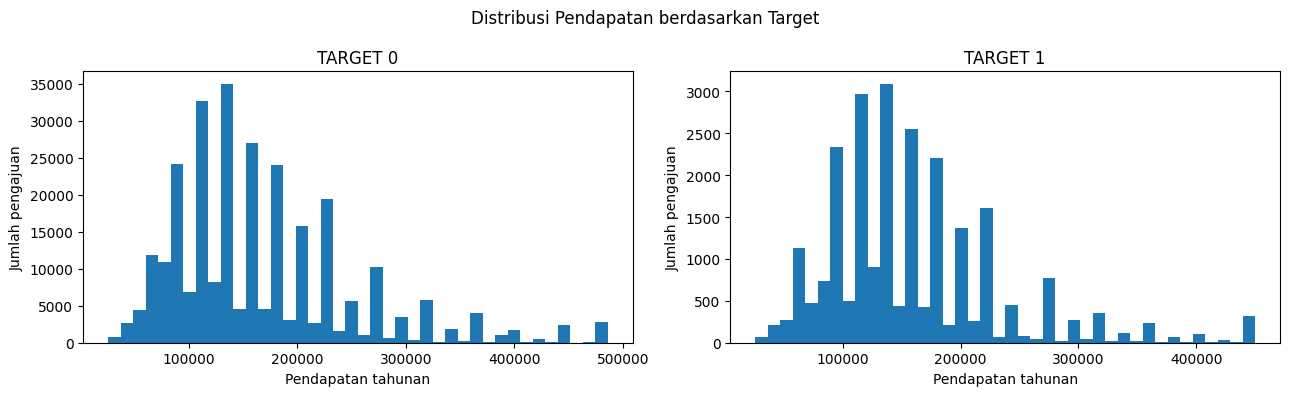

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for target, label in [
    (0, "TARGET 0"),
    (1, "TARGET 1")
]:
    values = eda.loc[
        eda["TARGET"] == target,
        "AMT_INCOME_TOTAL"
    ].dropna()

    axes[target].hist(
        values.clip(upper=values.quantile(0.99)),
        bins=40
    )

    axes[target].set_title(label)
    axes[target].set_xlabel("Pendapatan tahunan")
    axes[target].set_ylabel("Jumlah pengajuan")

plt.suptitle("Distribusi Pendapatan berdasarkan Target")
plt.tight_layout()
plt.show()

analisis rasio cicilan

In [17]:

# Kelompokkan rasio cicilan terhadap pendapatan
eda["ANNUITY_RATIO_GROUP"] = pd.cut(
    eda["ANNUITY_INCOME_RATIO"],
    bins=[-np.inf, 0.10, 0.20, 0.30, 0.40, np.inf],
    labels=[
        "<=10%",
        "10–20%",
        "20–30%",
        "30–40%",
        ">40%"
    ]
)

# Hitung jumlah pengajuan dan tingkat TARGET 1
ratio_analysis = eda.groupby(
    "ANNUITY_RATIO_GROUP",
    observed=False
).agg(
    Total=("TARGET", "size"),
    Kasus_Target_1=("TARGET", "sum"),
    Tingkat_Target_1=("TARGET", "mean")
)

ratio_analysis["Tingkat_Target_1"] = (
    ratio_analysis["Tingkat_Target_1"] * 100
).round(2)

display(ratio_analysis)


,Total,Kasus_Target_1,Tingkat_Target_1
ANNUITY_RATIO_GROUP,,,
<=10%,57210,4105,7.18
10–20%,145231,11701,8.06
20–30%,73742,6463,8.76
30–40%,23407,1902,8.13
>40%,7909,654,8.27


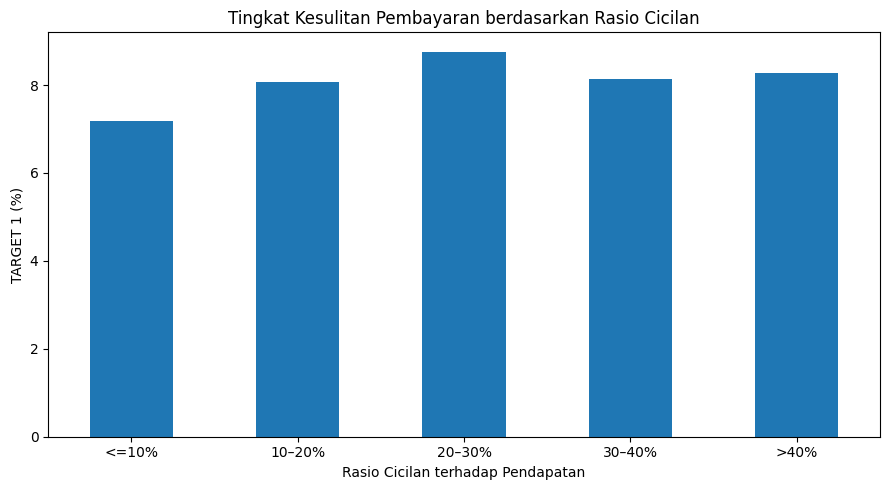

In [18]:

ratio_analysis["Tingkat_Target_1"].plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Tingkat Kesulitan Pembayaran berdasarkan Rasio Cicilan")
plt.xlabel("Rasio Cicilan terhadap Pendapatan")
plt.ylabel("TARGET 1 (%)")
plt.tight_layout()
plt.show()


Data menunjukkan bahwa tingkat kesulitan pembayaran cenderung meningkat dari kelompok rasio cicilan rendah hingga kelompok 20–30%, tetapi setelah itu polanya tidak terus meningkat. Jadi, hubungan antara rasio cicilan dan TARGET 1 tidak sepenuhnya linear.

Temuan penting:
- Kelompok ≤10%: memiliki tingkat TARGET 1 terendah, yaitu 7,18%.
- Kelompok 20–30%: memiliki tingkat TARGET 1 tertinggi, yaitu 8,76%.
- Kelompok >40%: tingkatnya 8,27%, lebih rendah daripada kelompok 20–30%.
- Selisih tertinggi dan terendah hanya 1,58 poin persentase.

Kesimpulannya, rasio cicilan terhadap pendapatan berpotensi menjadi salah satu fitur untuk analisis risiko kredit, tetapi belum cukup untuk dijadikan satu-satunya dasar penilaian. Kita perlu menguji pengaruhnya bersama variabel lain, seperti pendapatan, jumlah kredit, jenis pekerjaan, dan riwayat kredit.

preprocessing data

In [19]:

# Salin fitur awal yang relevan untuk analisis risiko kredit
selected_features = [
    "SK_ID_CURR",
    "TARGET",
    "NAME_CONTRACT_TYPE",
    "CODE_GENDER",
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY",
    "CNT_CHILDREN",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "OCCUPATION_TYPE",
    "CNT_FAM_MEMBERS",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]

model_df = df[selected_features].copy()

print("Ukuran dataset:", model_df.shape)
print("\nJumlah nilai kosong terbanyak:")
display(
    model_df.isna()
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nDistribusi target:")
display(
    model_df["TARGET"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Ukuran dataset: (307511, 22)

Jumlah nilai kosong terbanyak:


,0
EXT_SOURCE_1,173378
OCCUPATION_TYPE,96391
EXT_SOURCE_3,60965
EXT_SOURCE_2,660
AMT_GOODS_PRICE,278
AMT_ANNUITY,12
CNT_FAM_MEMBERS,2
FLAG_OWN_CAR,0
FLAG_OWN_REALTY,0
NAME_CONTRACT_TYPE,0



Distribusi target:


,proportion
TARGET,
0,91.93
1,8.07


Bagi data latih dan validasi

In [20]:

from sklearn.model_selection import train_test_split

# Pisahkan fitur dan target
X = model_df.drop(columns=["TARGET", "SK_ID_CURR"])
y = model_df["TARGET"]

# Bagi data: 80% latih dan 20% validasi
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Ukuran data latih:", X_train.shape)
print("Ukuran data validasi:", X_valid.shape)

print("\nProporsi TARGET data latih (%):")
display((y_train.value_counts(normalize=True) * 100).round(2))

print("\nProporsi TARGET data validasi (%):")
display((y_valid.value_counts(normalize=True) * 100).round(2))


Ukuran data latih: (246008, 20)
Ukuran data validasi: (61503, 20)

Proporsi TARGET data latih (%):


,proportion
TARGET,
0,91.93
1,8.07



Proporsi TARGET data validasi (%):


,proportion
TARGET,
0,91.93
1,8.07


Pembagian data berhasil dan proporsi TARGET pada data latih maupun validasi sama, yaitu 91,93% untuk TARGET 0 dan 8,07% untuk TARGET 1.

Preprocessing dan training model

In [21]:

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Identifikasi kolom numerik dan kategorikal
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Jumlah fitur numerik:", len(numeric_features))
print("Jumlah fitur kategorikal:", len(categorical_features))

# Preprocessing fitur numerik
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing fitur kategorikal
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Gabungkan preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Pipeline model
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Training
baseline_model.fit(X_train, y_train)

print("Training model baseline selesai.")


Jumlah fitur numerik: 11
Jumlah fitur kategorikal: 9
Training model baseline selesai.


Evaluasi model

In [22]:

# Prediksi kelas dan probabilitas TARGET 1
y_pred = baseline_model.predict(X_valid)
y_proba = baseline_model.predict_proba(X_valid)[:, 1]

# Evaluasi pada threshold default 0.5
metrics = pd.DataFrame({
    "Metrik": [
        "ROC-AUC",
        "PR-AUC (Average Precision)",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Nilai": [
        roc_auc_score(y_valid, y_proba),
        average_precision_score(y_valid, y_proba),
        accuracy_score(y_valid, y_pred),
        precision_score(y_valid, y_pred, zero_division=0),
        recall_score(y_valid, y_pred, zero_division=0),
        f1_score(y_valid, y_pred, zero_division=0)
    ]
})

metrics["Nilai"] = metrics["Nilai"].round(4)
display(metrics)

# Confusion matrix
cm = confusion_matrix(y_valid, y_pred)

cm_df = pd.DataFrame(
    cm,
    index=["Aktual TARGET 0", "Aktual TARGET 1"],
    columns=["Prediksi TARGET 0", "Prediksi TARGET 1"]
)

display(cm_df)


,Metrik,Nilai
0,ROC-AUC,0.7418
1,PR-AUC (Average Precision),0.2220
2,Accuracy,0.6872
3,Precision,0.1597
4,Recall,0.6747
5,F1-Score,0.2583


,Prediksi TARGET 0,Prediksi TARGET 1
Aktual TARGET 0,38915,17623
Aktual TARGET 1,1615,3350


Dari 4.965 kasus TARGET 1 aktual pada data validasi, model berhasil menemukan 3.350 kasus. Namun, model juga menandai 17.623 pengajuan TARGET 0 sebagai positif.
Kesimpulan sementara: dengan threshold 0,5, model cenderung lebih mengutamakan penangkapan kasus positif daripada menghindari false positive. Apakah ini tepat bergantung pada tujuan bisnis dan biaya kesalahan yang ditetapkan.

Optimalkan threshold

In [23]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid, y_pred_threshold
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_valid, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, y_pred_threshold, zero_division=0
        ),
        "F1_Score": f1_score(
            y_valid, y_pred_threshold, zero_division=0
        ),
        "False_Positive": fp,
        "False_Negative": fn,
        "True_Positive": tp
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.round(4)
)


,Threshold,Precision,Recall,F1_Score,False_Positive,False_Negative,True_Positive
0,0.2,0.0889,0.9748,0.1630,49581,125,4840
1,0.3,0.1053,0.9168,0.1889,38690,413,4552
2,0.4,0.1284,0.8062,0.2215,27182,962,4003
3,0.5,0.1597,0.6747,0.2583,17623,1615,3350
4,0.6,0.1981,0.5003,0.2838,10057,2481,2484
5,0.7,0.2540,0.3235,0.2846,4716,3359,1606


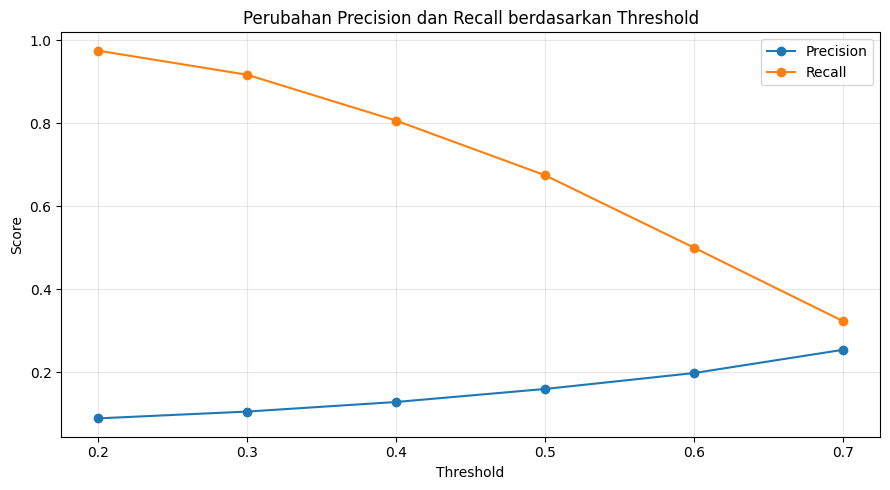

In [24]:

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Perubahan Precision dan Recall berdasarkan Threshold")
plt.xticks(thresholds)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Hasilnya menunjukkan bahwa menaikkan threshold membuat precision meningkat, tetapi recall menurun. Ini adalah kompromi utama saat menentukan batas prediksi risiko kredit.

2. Apa artinya untuk bisnis?
- Threshold 0,2: hampir semua kasus TARGET 1 berhasil ditemukan, tetapi jumlah pengajuan yang salah ditandai sebagai positif sangat besar.
- Threshold 0,5: model menangkap sekitar 67 dari setiap 100 kasus positif aktual, tetapi masih banyak false positive.
- Threshold 0,7: prediksi positif lebih tepat dibandingkan threshold yang lebih rendah, tetapi sekitar dua pertiga kasus positif aktual tidak terdeteksi.
Threshold terbaik bergantung pada konsekuensi kesalahan. Dalam analisis kredit, false negative berpotensi membuat risiko terlewat, sedangkan false positive berpotensi menyebabkan peminjam yang sebenarnya tidak mengalami kesulitan pembayaran ditandai berisiko.
Untuk tahap awal, threshold 0,6 layak dijadikan kandidat kompromi: precision naik menjadi 19,81%, recall masih 50,03%, dan jumlah false positive turun menjadi 10.057. Ini belum tentu threshold final karena keputusan akhirnya perlu mempertimbangkan biaya kesalahan bisnis.

Bandingkan dengan Random Forest

In [25]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        max_depth=12,
        min_samples_leaf=50,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

# Probabilitas prediksi kelas TARGET 1
rf_proba = rf_model.predict_proba(X_valid)[:, 1]

# Bandingkan performa berdasarkan skor probabilitas
model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC_AUC": roc_auc_score(y_valid, y_proba),
        "PR_AUC": average_precision_score(y_valid, y_proba)
    },
    {
        "Model": "Random Forest",
        "ROC_AUC": roc_auc_score(y_valid, rf_proba),
        "PR_AUC": average_precision_score(y_valid, rf_proba)
    }
])

display(model_comparison.round(4))


,Model,ROC_AUC,PR_AUC
0,Logistic Regression,0.7418,0.222
1,Random Forest,0.7459,0.225


Interpretasi: kedua model memiliki performa yang relatif mirip. Random Forest sedikit lebih baik dalam membedakan kelas berdasarkan ROC-AUC dan memperoleh PR-AUC sedikit lebih tinggi. Untuk portofolio, ini justru temuan yang baik: pemilihan model didasarkan pada hasil pengujian, bukan asumsi bahwa model yang lebih kompleks pasti lebih unggul.

Evaluasi Random Forest pada threshold berbeda

In [26]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

rf_threshold_results = []

for threshold in thresholds:
    rf_pred = (rf_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid, rf_pred
    ).ravel()

    rf_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_valid, rf_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, rf_pred, zero_division=0
        ),
        "F1_Score": f1_score(
            y_valid, rf_pred, zero_division=0
        ),
        "False_Positive": fp,
        "False_Negative": fn,
        "True_Positive": tp
    })

rf_threshold_df = pd.DataFrame(rf_threshold_results)

display(rf_threshold_df.round(4))


,Threshold,Precision,Recall,F1_Score,False_Positive,False_Negative,True_Positive
0,0.2,0.0842,0.9925,0.1552,53617,37,4928
1,0.3,0.0996,0.9434,0.1802,42329,281,4684
2,0.4,0.1278,0.8252,0.2213,27971,868,4097
3,0.5,0.1694,0.6381,0.2677,15532,1797,3168
4,0.6,0.2282,0.3984,0.2902,6688,2987,1978
5,0.7,0.3188,0.1515,0.2054,1607,4213,752


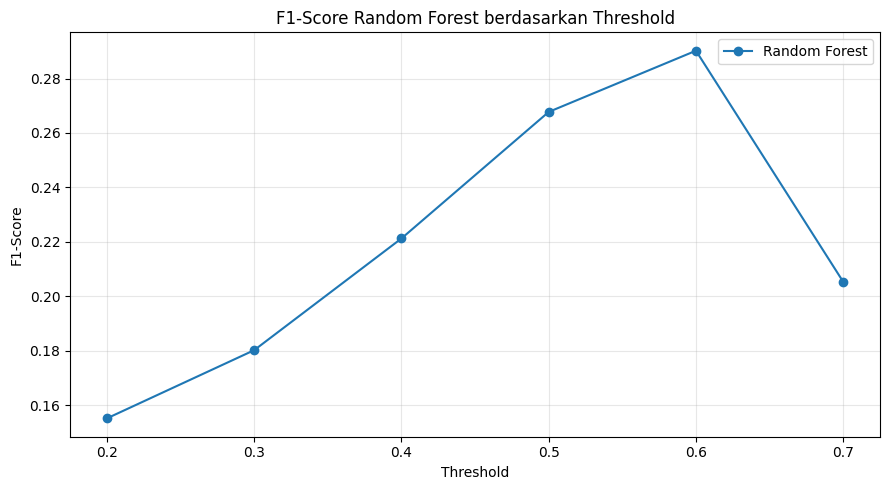

In [27]:

plt.figure(figsize=(9, 5))

plt.plot(
    rf_threshold_df["Threshold"],
    rf_threshold_df["F1_Score"],
    marker="o",
    label="Random Forest"
)

plt.xlabel("Threshold")
plt.ylabel("F1-Score")
plt.title("F1-Score Random Forest berdasarkan Threshold")
plt.xticks(thresholds)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Hasil Random Forest sudah menunjukkan pola yang cukup jelas. F1-Score tertinggi pada tabel ada di threshold 0,6, yaitu 0,2902. Namun, threshold terbaik untuk proyek ini tetap bergantung pada tujuan bisnis dan biaya kesalahan prediksi.

identifikasi fitur yang berpengaruh

,Feature,Importance
10,num__EXT_SOURCE_3,0.24229
9,num__EXT_SOURCE_2,0.22446
8,num__EXT_SOURCE_1,0.08918
5,num__DAYS_BIRTH,0.06469
6,num__DAYS_EMPLOYED,0.05473
4,num__AMT_GOODS_PRICE,0.04255
2,num__AMT_CREDIT,0.03949
3,num__AMT_ANNUITY,0.03573
29,cat__NAME_EDUCATION_TYPE_Higher education,0.02307
1,num__AMT_INCOME_TOTAL,0.01980


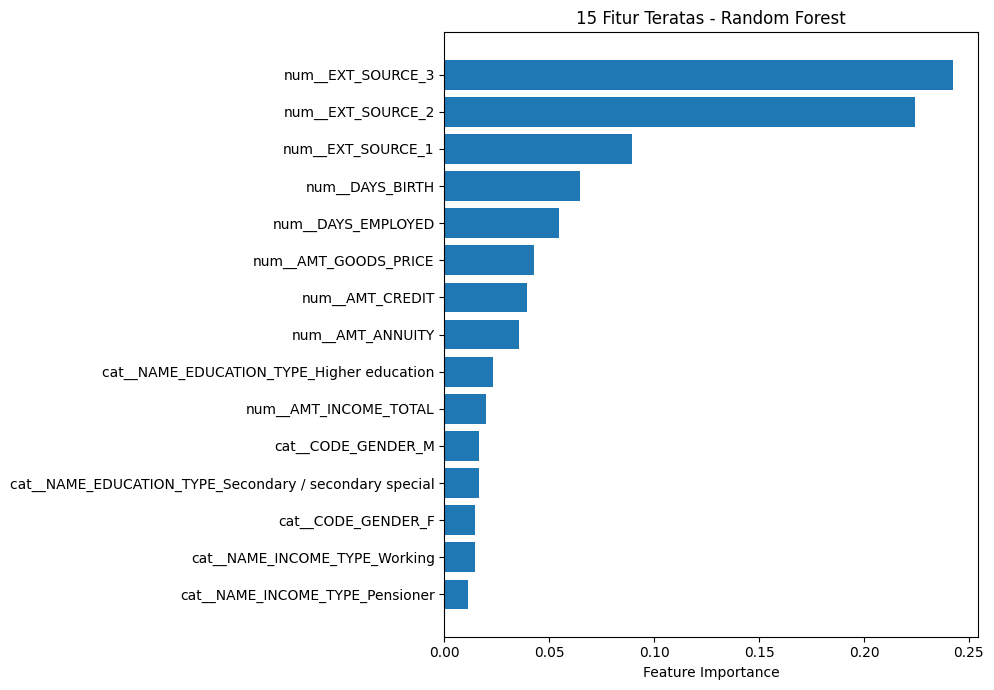

In [28]:

# Ambil preprocessing dan classifier dari pipeline
fitted_preprocessor = rf_model.named_steps["preprocessor"]
rf_classifier = rf_model.named_steps["classifier"]

# Ambil nama fitur setelah preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Ambil feature importance dari Random Forest
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
}).sort_values("Importance", ascending=False)

# Tampilkan 20 fitur teratas
display(importance_df.head(20).round(5))

# Visualisasi 15 fitur teratas
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.xlabel("Feature Importance")
plt.title("15 Fitur Teratas - Random Forest")
plt.tight_layout()
plt.show()


In [ ]:
Insight bisnis untuk portofolio
Temuan sementara yang dapat ditulis:
- Skor eksternal mendominasi prediksi. Model banyak memanfaatkan informasi dari ketiga fitur EXT_SOURCE; definisi dan sumber detailnya perlu merujuk pada dokumentasi dataset.
- Karakteristik pemohon juga relevan. Usia dan masa kerja berada di posisi berikutnya.
- Informasi finansial tetap berkontribusi. Harga barang, jumlah kredit, cicilan, dan pendapatan turut digunakan model, tetapi importance masing-masing lebih rendah daripada fitur skor eksternal.
- Kualitas dan ketersediaan data penting. EXT_SOURCE_1 memiliki nilai kosong dalam jumlah besar, sehingga hasil pemodelan perlu ditafsirkan dengan mempertimbangkan kualitas fitur tersebut.

Periksa arah hubungan fitur utama

In [29]:

from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    rf_model,
    X_valid,
    y_valid,
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_valid.columns,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_Std": perm_result.importances_std
}).sort_values("Importance_Mean", ascending=False)

display(permutation_df.head(15).round(5))



,Feature,Importance_Mean,Importance_Std
18,EXT_SOURCE_2,0.05584,0.00044
19,EXT_SOURCE_3,0.05350,0.00224
17,EXT_SOURCE_1,0.01406,0.00189
10,NAME_EDUCATION_TYPE,0.01159,0.00117
8,AMT_GOODS_PRICE,0.00845,0.00067
1,CODE_GENDER,0.00843,0.00037
13,DAYS_BIRTH,0.00631,0.00116
0,NAME_CONTRACT_TYPE,0.00540,0.00041
14,DAYS_EMPLOYED,0.00479,0.00070
7,AMT_ANNUITY,0.00366,0.00055


Temuan utama:
- Ketiga fitur EXT_SOURCE menempati tiga posisi teratas.
- NAME_EDUCATION_TYPE menjadi fitur kategorikal dengan kontribusi tertinggi pada hasil ini.
- CODE_GENDER dan DAYS_BIRTH juga berkontribusi, tetapi penggunaannya dalam keputusan kredit perlu ditinjau dari sisi keadilan dan regulasi.
- OCCUPATION_TYPE dan NAME_FAMILY_STATUS menunjukkan kontribusi relatif kecil pada model ini.
Catatan: Permutation importance mengukur seberapa besar performa model menurun ketika nilai suatu fitur diacak. Angka positif yang lebih besar berarti fitur tersebut lebih berguna bagi model. Hasil ini tidak membuktikan hubungan sebab-akibat dan tidak menunjukkan apakah suatu fitur meningkatkan atau menurunkan risiko.

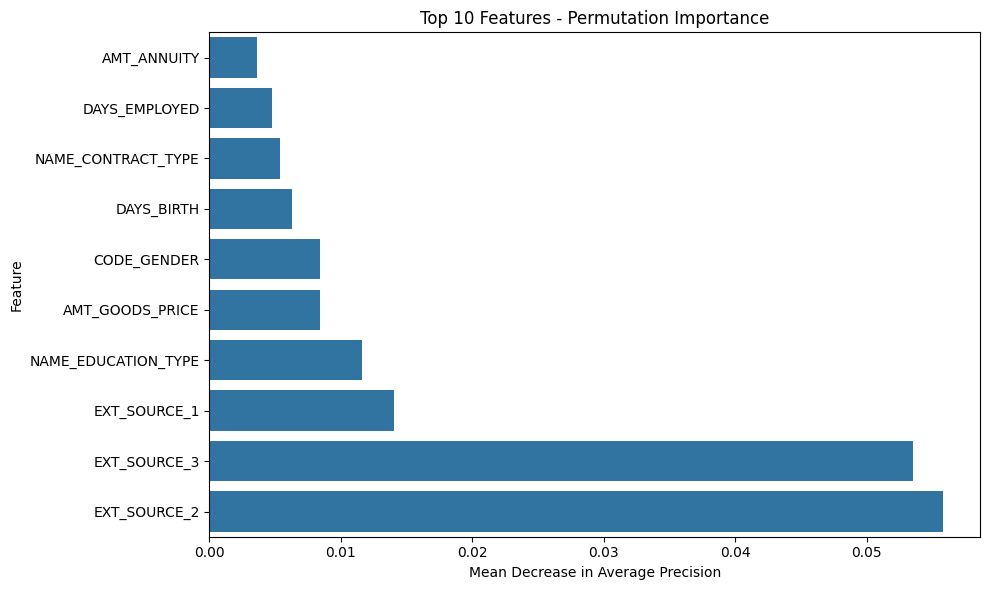

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

top_features = permutation_df.head(10).sort_values(
    "Importance_Mean", ascending=True
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance_Mean",
    y="Feature"
)

plt.title("Top 10 Features - Permutation Importance")
plt.xlabel("Mean Decrease in Average Precision")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Feature Importance Analysis

Berdasarkan hasil permutation importance pada data validasi, `EXT_SOURCE_2` memiliki kontribusi prediktif tertinggi dengan nilai importance sebesar 0,05584, diikuti oleh `EXT_SOURCE_3` sebesar 0,05350 dan `EXT_SOURCE_1` sebesar 0,01406. Hasil ini menunjukkan bahwa informasi dari ketiga fitur tersebut berperan penting dalam mempertahankan kemampuan model Random Forest untuk membedakan pemohon dengan dan tanpa kesulitan pembayaran.

Selain itu, `NAME_EDUCATION_TYPE`, `AMT_GOODS_PRICE`, dan `CODE_GENDER` termasuk fitur dengan kontribusi relatif tinggi dibandingkan fitur lainnya. Namun, permutation importance hanya menunjukkan kontribusi suatu fitur terhadap performa prediksi model, bukan hubungan kausal maupun arah pengaruhnya terhadap risiko.

Temuan ini dapat menjadi dasar untuk analisis lanjutan, termasuk evaluasi kualitas fitur, interpretasi model, dan pengujian fairness sebelum model dipertimbangkan untuk mendukung keputusan kredit. Dataset yang digunakan berasal dari Home Credit dan tidak secara langsung merepresentasikan karakteristik peminjam pada industri Pindar di Indonesia.

Bandingkan performa kedua model

In [31]:

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Prediksi probabilitas dari kedua model
logistic_proba = baseline_model.predict_proba(X_valid)[:, 1]
rf_proba = rf_model.predict_proba(X_valid)[:, 1]

# Evaluasi pada threshold default 0.50
models = {
    "Logistic Regression": logistic_proba,
    "Random Forest": rf_proba
}

results = []

for model_name, proba in models.items():
    pred = (proba >= 0.50).astype(int)

    results.append({
        "Model": model_name,
        "ROC_AUC": roc_auc_score(y_valid, proba),
        "PR_AUC": average_precision_score(y_valid, proba),
        "Precision": precision_score(y_valid, pred, zero_division=0),
        "Recall": recall_score(y_valid, pred, zero_division=0),
        "F1_Score": f1_score(y_valid, pred, zero_division=0)
    })

evaluation_df = pd.DataFrame(results)

display(
    evaluation_df
    .sort_values("PR_AUC", ascending=False)
    .round(4)
)


,Model,ROC_AUC,PR_AUC,Precision,Recall,F1_Score
1,Random Forest,0.7459,0.225,0.1694,0.6381,0.2677
0,Logistic Regression,0.7418,0.222,0.1597,0.6747,0.2583


Kesimpulan sementara: Random Forest menjadi kandidat model terbaik karena unggul pada ROC-AUC, PR-AUC, precision, dan F1-score. Namun, Logistic Regression memiliki recall lebih tinggi, sehingga berhasil mendeteksi proporsi kasus kesulitan pembayaran yang lebih besar pada threshold tersebut.
Perbedaannya relatif kecil. Jadi, kita belum bisa menyatakan Random Forest unggul secara signifikan tanpa pengujian tambahan.

In [32]:

from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix
)

threshold_results = []

for model_name, proba in models.items():
    for threshold in [0.40, 0.50, 0.60]:
        pred = (proba >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            y_valid, pred, labels=[0, 1]
        ).ravel()

        threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_valid, pred, zero_division=0
            ),
            "Recall": recall_score(
                y_valid, pred, zero_division=0
            ),
            "F1_Score": f1_score(
                y_valid, pred, zero_division=0
            ),
            "True_Positive": tp,
            "False_Positive": fp,
            "False_Negative": fn,
            "True_Negative": tn
        })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.round(4)
)


,Model,Threshold,Precision,Recall,F1_Score,True_Positive,False_Positive,False_Negative,True_Negative
0,Logistic Regression,0.4,0.1284,0.8062,0.2215,4003,27182,962,29356
1,Logistic Regression,0.5,0.1597,0.6747,0.2583,3350,17623,1615,38915
2,Logistic Regression,0.6,0.1981,0.5003,0.2838,2484,10057,2481,46481
3,Random Forest,0.4,0.1278,0.8252,0.2213,4097,27971,868,28567
4,Random Forest,0.5,0.1694,0.6381,0.2677,3168,15532,1797,41006
5,Random Forest,0.6,0.2282,0.3984,0.2902,1978,6688,2987,49850


Ada tiga temuan utama:
- Recall tertinggi: Random Forest pada threshold 0,40, yaitu 82,52%. Model mendeteksi lebih banyak kasus kesulitan pembayaran, tetapi false positive juga sangat tinggi.
- F1-score tertinggi: Random Forest pada threshold 0,60, yaitu 0,2902. Ini merupakan keseimbangan precision dan recall terbaik di antara enam skenario yang diuji.
- Precision tertinggi: Random Forest pada threshold 0,60, yaitu 22,82%. Namun, dari kasus yang ditandai berisiko, mayoritas masih merupakan false positive.

Buat confusion matrix final

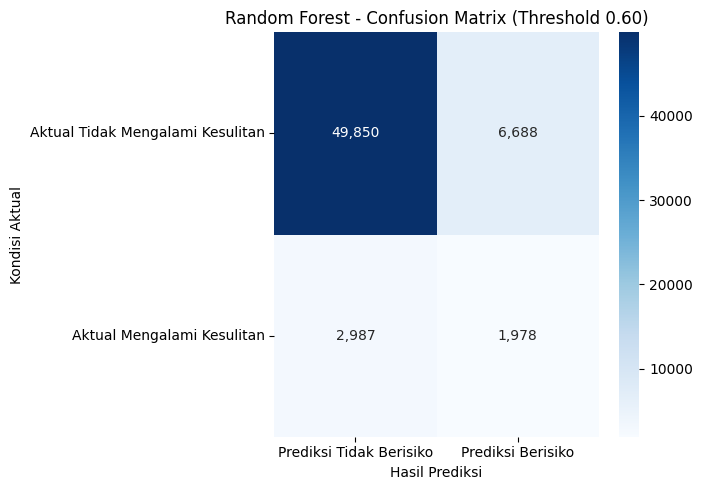

                           precision    recall  f1-score   support

Tidak Mengalami Kesulitan       0.94      0.88      0.91     56538
      Mengalami Kesulitan       0.23      0.40      0.29      4965

                 accuracy                           0.84     61503
                macro avg       0.59      0.64      0.60     61503
             weighted avg       0.89      0.84      0.86     61503



In [33]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Model kandidat dan threshold
final_model = rf_model
final_threshold = 0.60

final_proba = final_model.predict_proba(X_valid)[:, 1]
final_pred = (final_proba >= final_threshold).astype(int)

# Confusion matrix
cm = confusion_matrix(y_valid, final_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=["Prediksi Tidak Berisiko", "Prediksi Berisiko"],
    yticklabels=["Aktual Tidak Mengalami Kesulitan", "Aktual Mengalami Kesulitan"]
)

plt.title("Random Forest - Confusion Matrix (Threshold 0.60)")
plt.xlabel("Hasil Prediksi")
plt.ylabel("Kondisi Aktual")
plt.tight_layout()
plt.show()

print(classification_report(
    y_valid,
    final_pred,
    target_names=["Tidak Mengalami Kesulitan", "Mengalami Kesulitan"],
    zero_division=0
))


Catatan penting: accuracy sebesar 84% tidak berarti model sudah sangat akurat dalam mendeteksi risiko. Data didominasi kelas tidak mengalami kesulitan, sehingga metrik kelas minoritas seperti precision, recall, dan F1-score lebih relevan.
Dari hasil threshold 0,60, model mendeteksi 1.978 kasus dengan benar, melewatkan 2.987 kasus kesulitan pembayaran, dan menghasilkan 6.688 false positive.

### Model Evaluation and Business Insights

Random Forest dipilih sebagai kandidat model utama dengan threshold 0,60 karena menghasilkan F1-score sebesar 0,2902 dan precision sebesar 0,2282 pada pengujian threshold yang telah dilakukan. Model memiliki ROC-AUC sebesar 0,7459 dan PR-AUC sebesar 0,2250, yang menunjukkan kemampuan membedakan kelas lebih baik daripada baseline sederhana, tetapi performanya masih memiliki keterbatasan.

Pada data validasi, model mencapai recall sebesar 39,84% untuk kelas yang mengalami kesulitan pembayaran. Artinya, model berhasil mengidentifikasi sebagian kasus berisiko, tetapi masih melewatkan sekitar 60% kasus aktual pada threshold tersebut. Precision sebesar 22,82% juga menunjukkan bahwa sebagian besar prediksi berisiko merupakan false positive.

Hasil ini memperlihatkan adanya trade-off antara mendeteksi lebih banyak kasus berisiko dan mengurangi kesalahan penandaan. Oleh karena itu, threshold 0,60 merupakan kandidat untuk evaluasi lanjutan, bukan keputusan final untuk penerapan operasional. Pemilihan threshold perlu mempertimbangkan biaya kesalahan prediksi, kalibrasi probabilitas, fairness, serta validasi pada data yang sesuai dengan konteks penerapan.

Analisis ini menggunakan dataset Home Credit internasional. Hasilnya tidak dapat langsung digeneralisasi untuk menggambarkan risiko peminjam Pindar di Indonesia.

In [34]:

# Menyiapkan tabel hasil prediksi pada data validasi
risk_results = X_valid.copy()

risk_results["TARGET_ACTUAL"] = y_valid.to_numpy()
risk_results["RISK_PROBABILITY"] = final_proba
risk_results["RISK_PREDICTION"] = final_pred
risk_results["THRESHOLD"] = final_threshold

risk_results["PREDICTION_RESULT"] = np.select(
    [
        (risk_results["TARGET_ACTUAL"] == 1) &
        (risk_results["RISK_PREDICTION"] == 1),

        (risk_results["TARGET_ACTUAL"] == 0) &
        (risk_results["RISK_PREDICTION"] == 1),

        (risk_results["TARGET_ACTUAL"] == 1) &
        (risk_results["RISK_PREDICTION"] == 0)
    ],
    [
        "True Positive",
        "False Positive",
        "False Negative"
    ],
    default="True Negative"
)

display(risk_results.head())
print("Shape:", risk_results.shape)


,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,...,OCCUPATION_TYPE,CNT_FAM_MEMBERS,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,TARGET_ACTUAL,RISK_PROBABILITY,RISK_PREDICTION,THRESHOLD,PREDICTION_RESULT
256571,Cash loans,M,Y,Y,1,157500.0,770292.0,30676.5,688500.0,Working,...,Laborers,3.0,NaN,0.594327,0.427657,0,0.437957,0,0.6,True Negative
191493,Cash loans,F,N,N,0,90000.0,364896.0,19926.0,315000.0,Working,...,Laborers,2.0,0.593554,0.619621,0.484851,0,0.324514,0,0.6,True Negative
103497,Cash loans,M,N,Y,0,148500.0,284400.0,18643.5,225000.0,Working,...,Security staff,2.0,NaN,0.030108,0.538863,0,0.687538,1,0.6,False Positive
130646,Cash loans,F,N,N,0,188100.0,976711.5,38218.5,873000.0,Working,...,Core staff,1.0,0.628656,0.417593,0.411849,0,0.376828,0,0.6,True Negative
211898,Cash loans,F,N,Y,0,180000.0,323194.5,19660.5,279000.0,Working,...,Laborers,2.0,NaN,0.355126,0.593718,0,0.524385,0,0.6,True Negative


Shape: (61503, 25)


In [35]:

# 1. Ekspor hasil prediksi
risk_results.to_csv(
    "credit_risk_predictions.csv",
    index=False
)

# 2. Buat tabel ringkasan performa model
model_summary = evaluation_df.copy()

model_summary.to_csv(
    "credit_risk_model_comparison.csv",
    index=False
)

# 3. Buat tabel evaluasi threshold
threshold_df.to_csv(
    "credit_risk_threshold_comparison.csv",
    index=False
)

print("File berhasil dibuat:")
print("- credit_risk_predictions.csv")
print("- credit_risk_model_comparison.csv")
print("- credit_risk_threshold_comparison.csv")


File berhasil dibuat:
- credit_risk_predictions.csv
- credit_risk_model_comparison.csv
- credit_risk_threshold_comparison.csv


In [36]:

from google.colab import files

files.download("credit_risk_predictions.csv")
files.download("credit_risk_model_comparison.csv")
files.download("credit_risk_threshold_comparison.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Visualisasi 1. Distribusi target aktual

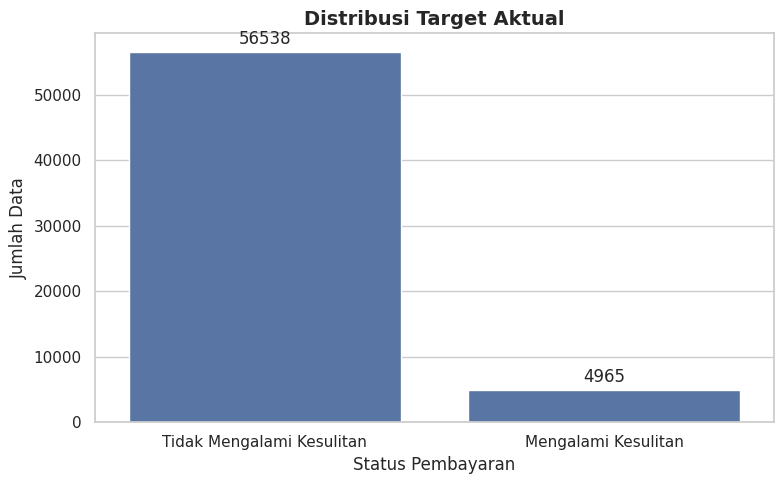

In [37]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

target_counts = risk_results["TARGET_ACTUAL"].map({
    0: "Tidak Mengalami Kesulitan",
    1: "Mengalami Kesulitan"
}).value_counts()

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=target_counts.index,
    y=target_counts.values
)

plt.title("Distribusi Target Aktual", fontsize=14, fontweight="bold")
plt.xlabel("Status Pembayaran")
plt.ylabel("Jumlah Data")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()


Visualisasi 2. Distribusi probabilitas risiko

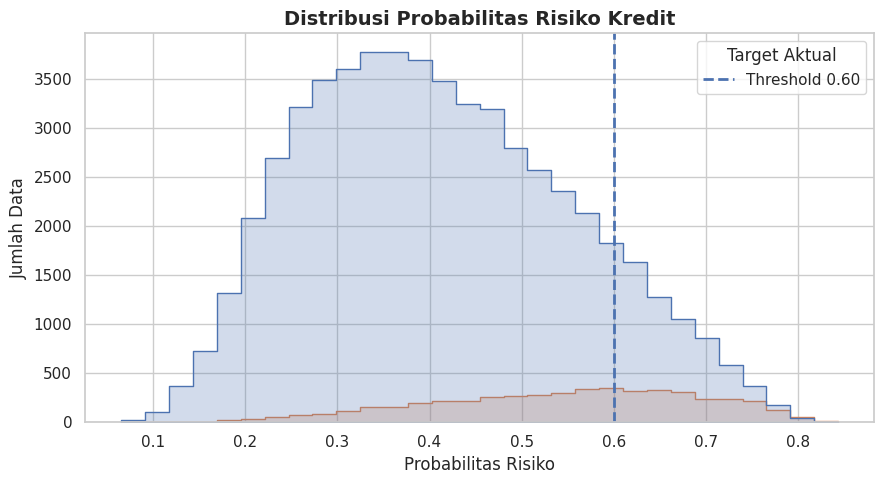

In [38]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=risk_results,
    x="RISK_PROBABILITY",
    hue="TARGET_ACTUAL",
    bins=30,
    stat="count",
    common_norm=False,
    element="step"
)

plt.axvline(
    0.60,
    linestyle="--",
    linewidth=2,
    label="Threshold 0.60"
)

plt.title("Distribusi Probabilitas Risiko Kredit", fontsize=14, fontweight="bold")
plt.xlabel("Probabilitas Risiko")
plt.ylabel("Jumlah Data")
plt.legend(title="Target Aktual")
plt.tight_layout()
plt.show()


Visualisasi 3. Confusion matrix

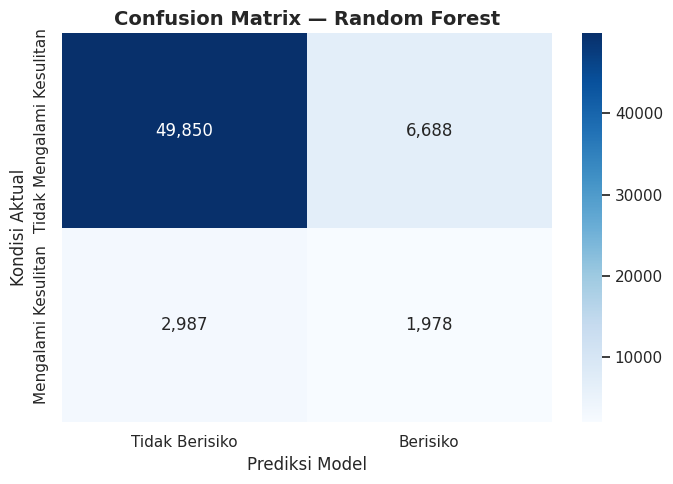

In [39]:

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    risk_results["TARGET_ACTUAL"],
    risk_results["RISK_PREDICTION"],
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=["Tidak Berisiko", "Berisiko"],
    yticklabels=["Tidak Mengalami Kesulitan", "Mengalami Kesulitan"]
)

plt.title("Confusion Matrix — Random Forest", fontsize=14, fontweight="bold")
plt.xlabel("Prediksi Model")
plt.ylabel("Kondisi Aktual")
plt.tight_layout()
plt.show()


Visualisasi 4. Hasil klasifikasi model

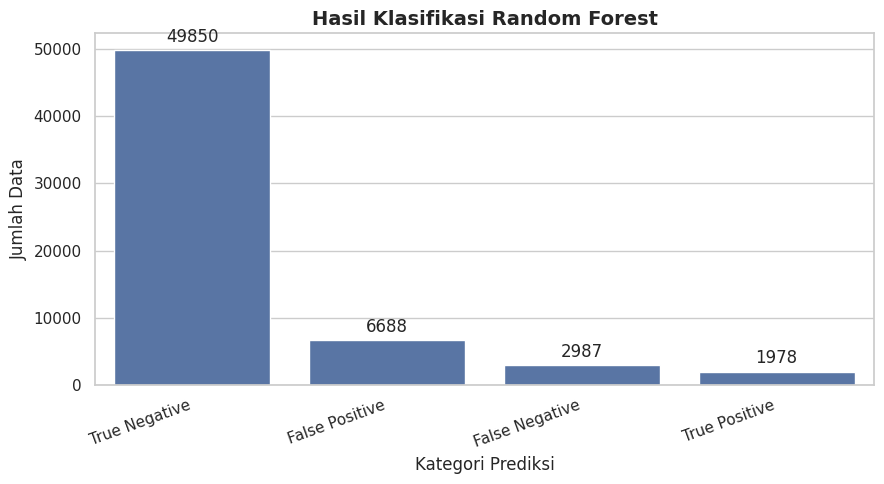

In [40]:

result_counts = risk_results["PREDICTION_RESULT"].value_counts()

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    x=result_counts.index,
    y=result_counts.values
)

plt.title("Hasil Klasifikasi Random Forest", fontsize=14, fontweight="bold")
plt.xlabel("Kategori Prediksi")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=20, ha="right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()


Simpan grafik untuk portofolio

In [41]:
plt.savefig(
    "confusion_matrix_random_forest.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

<Figure size 640x480 with 0 Axes>

Visualisasi evaluasi model

1. ROC Curve — membandingkan kemampuan model

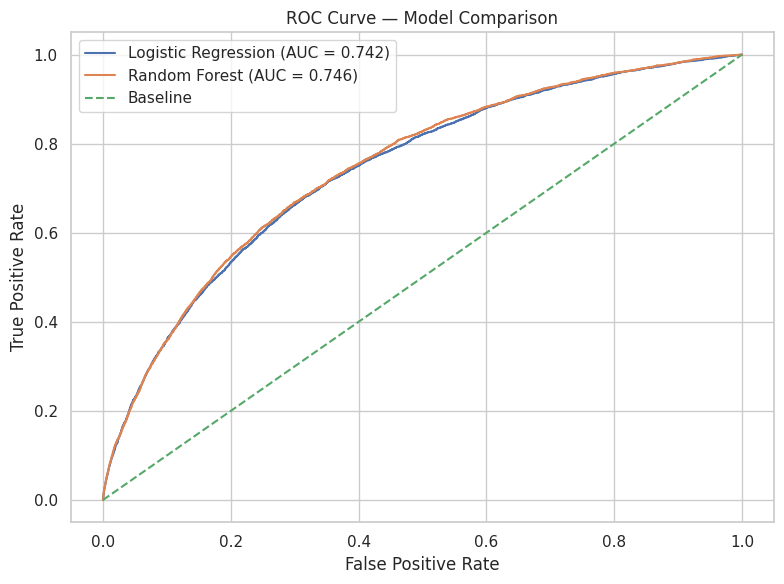

In [43]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for name, proba in [
    ("Logistic Regression", logistic_proba),
    ("Random Forest", rf_proba)
]:
    fpr, tpr, _ = roc_curve(y_valid, proba)
    auc_score = roc_auc_score(y_valid, proba)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Baseline")
plt.title("ROC Curve — Model Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

2. Precision-Recall Curve

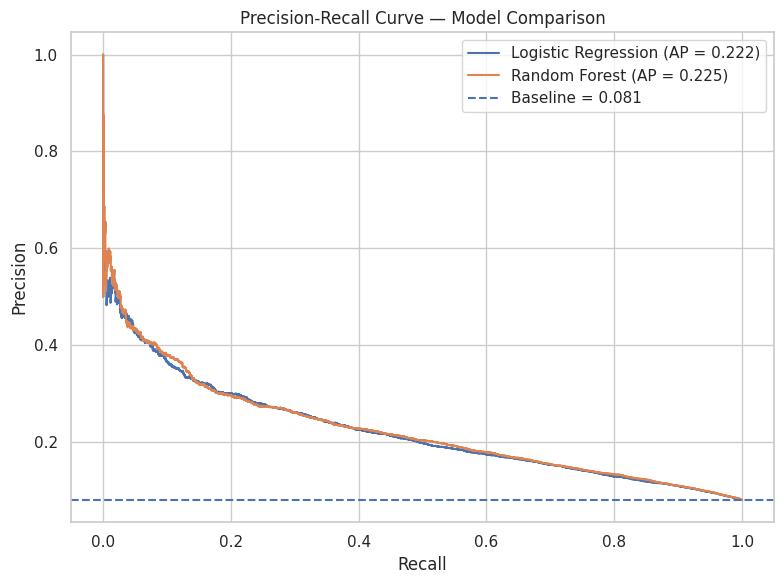

In [45]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for name, proba in [
    ("Logistic Regression", logistic_proba),
    ("Random Forest", rf_proba)
]:
    precision, recall, _ = precision_recall_curve(y_valid, proba)
    ap = average_precision_score(y_valid, proba)

    plt.plot(recall, precision, label=f"{name} (AP = {ap:.3f})")

plt.axhline(
    y_valid.mean(),
    linestyle="--",
    label=f"Baseline = {y_valid.mean():.3f}"
)

plt.title("Precision-Recall Curve — Model Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.tight_layout()
plt.show()

3. Feature Importance — faktor yang membantu prediksi

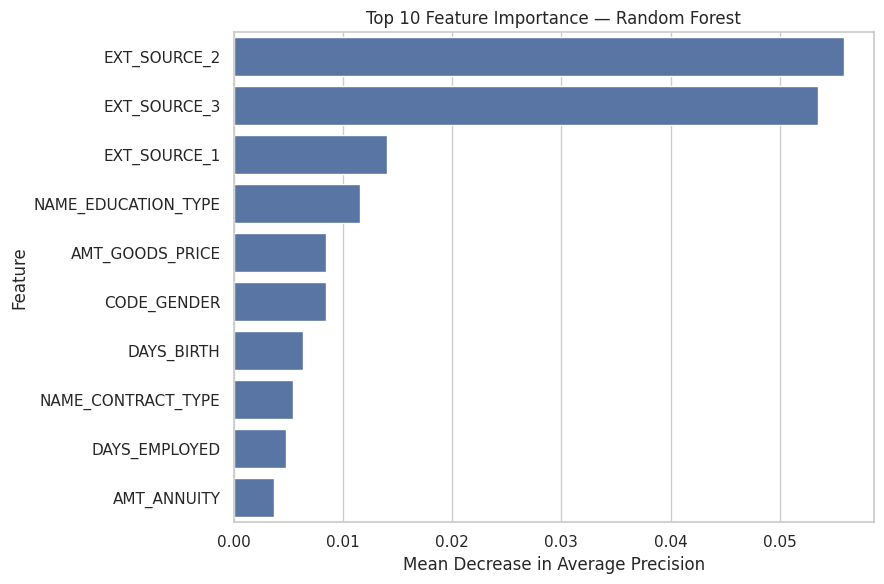

In [47]:

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Menggunakan rf_model sebagai pengganti rf_pipeline
perm_result = permutation_importance(
    rf_model,
    X_valid,
    y_valid,
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_valid.columns,
    "Importance": perm_result.importances_mean
}).sort_values("Importance", ascending=False).head(10)

plt.figure(figsize=(9, 6))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importance — Random Forest")
plt.xlabel("Mean Decrease in Average Precision")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()
